In [16]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")


PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [17]:

from torchvision import datasets, transforms
import matplotlib.pyplot as plt

transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="/content/data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Image shape:", train_data[0][0].shape)


100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.85MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.5MB/s]

Training images: 60000
Testing images: 10000
Image shape: torch.Size([1, 28, 28])


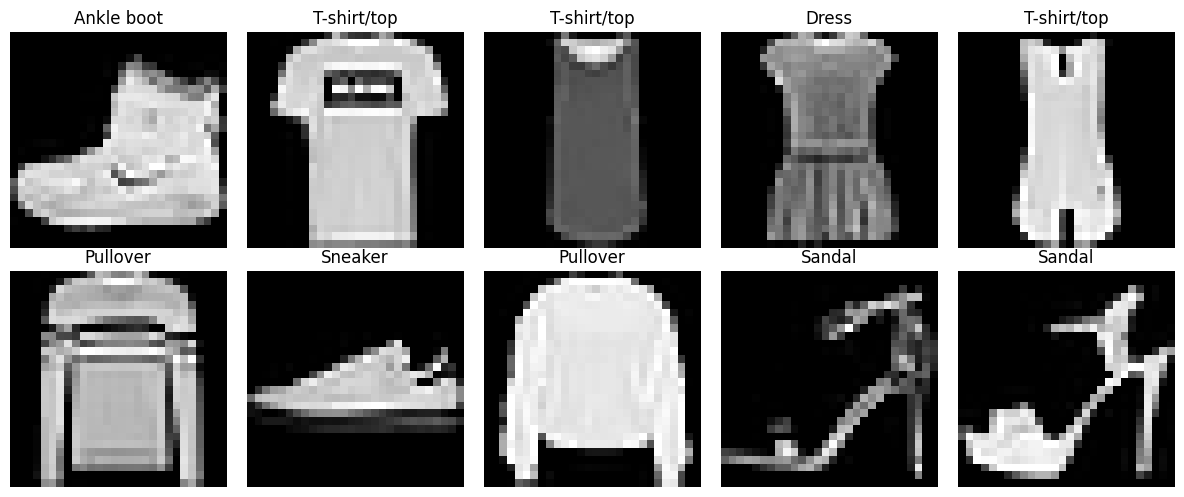

In [18]:

class_names = train_data.classes

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [19]:

import torch
from torch.utils.data import random_split

# กำหนด seed เพื่อให้แบ่งข้อมูลได้เหมือนเดิมทุกครั้ง
generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    train_data,
    [54000, 6000],
    generator=generator
)

print("Train images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_data))


Train images: 54000
Validation images: 6000
Test images: 10000


In [20]:

from torch.utils.data import DataLoader

batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

# ทดลองดึงข้อมูล 1 batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())


Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
First 10 labels: [0, 5, 4, 5, 0, 4, 3, 3, 2, 0]


In [21]:

import torch
import torch.nn as nn

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # ภาพเข้า: [1, 28, 28]
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # ขนาดภาพเหลือ [16, 14, 14]
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)

            # ขนาดภาพเหลือ [32, 7, 7]
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# สร้างโมเดล
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = FashionCNN().to(device)

print("Device:", device)
print(model)

# ทดลองส่งภาพเข้าโมเดล 1 batch
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)


Device: cuda
FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Input shape: torch.Size([128, 1, 28, 28])
Output shape: torch.Size([128, 10])


In [22]:

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

epochs = 8

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Epochs:", epochs)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))


Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Epochs: 8
Trainable parameters: 206922


In [23]:

import copy
import torch

best_val_acc = 0.0
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(epochs):

    # ===== 1. ฝึกโมเดล =====
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # ล้าง gradient จากรอบก่อน
        optimizer.zero_grad()

        # ให้โมเดลทำนาย
        outputs = model(images)

        # คำนวณความผิดพลาด
        loss = criterion(outputs, labels)

        # คำนวณ gradient
        loss.backward()

        # ปรับน้ำหนักโมเดล
        optimizer.step()

        # เก็บสถิติ
        train_loss_sum += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ===== 2. ตรวจสอบ Validation =====
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # เก็บโมเดลที่มี Validation Accuracy ดีที่สุด
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

# โหลดน้ำหนักจากรอบที่ Validation Accuracy ดีที่สุด
model.load_state_dict(best_model_state)

# บันทึกโมเดล
torch.save(model.state_dict(), "/content/best_fashion_cnn.pth")

print("\nTraining complete!")
print(f"Best Validation Accuracy: {best_val_acc:.2%}")
print("Model saved to /content/best_fashion_cnn.pth")


Epoch [1/8] | Train Loss: 0.6436 | Train Acc: 76.67% | Val Loss: 0.4086 | Val Acc: 85.15%
Epoch [2/8] | Train Loss: 0.3962 | Train Acc: 85.75% | Val Loss: 0.3700 | Val Acc: 86.90%
Epoch [3/8] | Train Loss: 0.3442 | Train Acc: 87.66% | Val Loss: 0.3073 | Val Acc: 88.95%
Epoch [4/8] | Train Loss: 0.3168 | Train Acc: 88.56% | Val Loss: 0.2926 | Val Acc: 89.37%
Epoch [5/8] | Train Loss: 0.2952 | Train Acc: 89.24% | Val Loss: 0.2822 | Val Acc: 89.73%
Epoch [6/8] | Train Loss: 0.2767 | Train Acc: 89.97% | Val Loss: 0.2743 | Val Acc: 89.85%
Epoch [7/8] | Train Loss: 0.2651 | Train Acc: 90.37% | Val Loss: 0.2677 | Val Acc: 90.05%
Epoch [8/8] | Train Loss: 0.2532 | Train Acc: 90.87% | Val Loss: 0.2557 | Val Acc: 90.63%

Training complete!
Best Validation Accuracy: 90.63%
Model saved to /content/best_fashion_cnn.pth


In [24]:
model.eval()          # ปิด Dropout เพราะตอนทดสอบต้องการผลคงที่
correct = 0
total = 0

with torch.no_grad():  # ไม่ต้องคำนวณ gradient ประหยัดเวลาและหน่วยความจำ
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)   # เลือกคลาสที่คะแนนสูงสุด

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Test Accuracy: {correct / total:.2%}")

Test Accuracy: 90.28%


              precision    recall  f1-score   support

 T-shirt/top      0.890     0.812     0.849      1000
     Trouser      0.990     0.978     0.984      1000
    Pullover      0.886     0.804     0.843      1000
       Dress      0.909     0.909     0.909      1000
        Coat      0.813     0.874     0.842      1000
      Sandal      0.968     0.987     0.977      1000
       Shirt      0.695     0.779     0.735      1000
     Sneaker      0.938     0.965     0.951      1000
         Bag      0.987     0.979     0.983      1000
  Ankle boot      0.984     0.941     0.962      1000

    accuracy                          0.903     10000
   macro avg      0.906     0.903     0.904     10000
weighted avg      0.906     0.903     0.904     10000



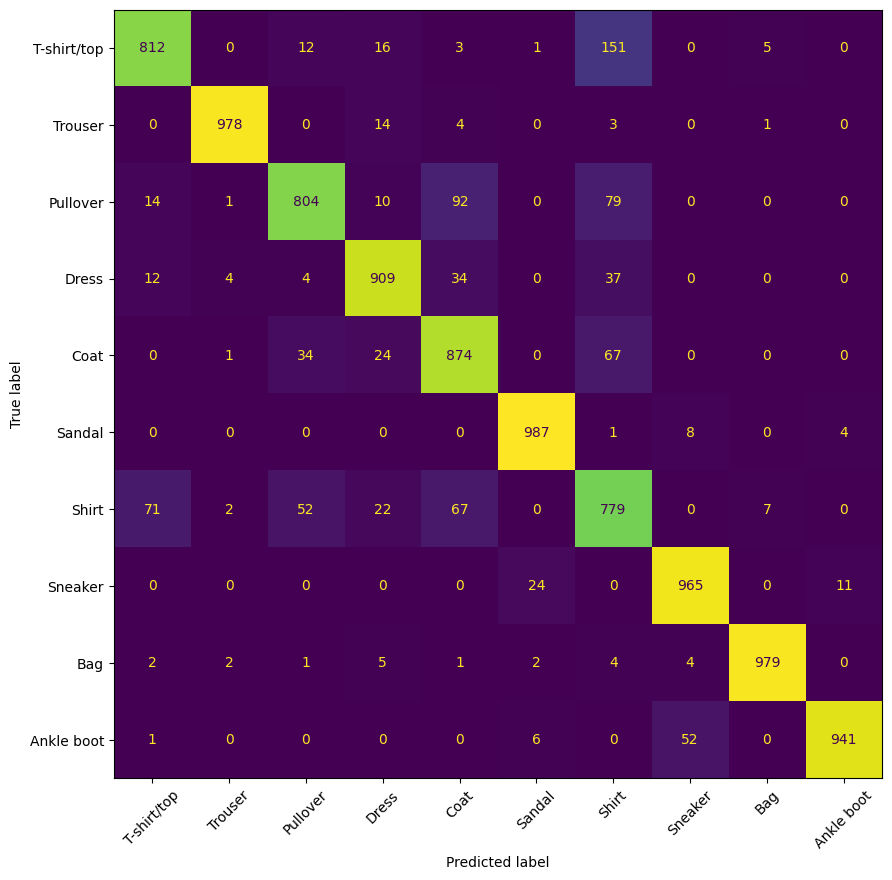

In [25]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# 1) เก็บคำทำนายและคำตอบจริงของ test set ทั้งหมด
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        preds = outputs.argmax(dim=1).cpu()      # .cpu() ย้ายกลับมาจาก GPU
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.tolist())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# 2) รายงานความแม่นยำแยกรายคลาส
print(classification_report(all_labels, all_preds,
                            target_names=class_names, digits=3))

# 3) วาด Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, colorbar=False
)
plt.tight_layout()
plt.show()

จำนวนรูปที่ทายผิด: 972


/tmp/ipykernel_1107/942718201.py:18: UserWarning: Glyph 3592 (\N{THAI CHARACTER CHO CHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1107/942718201.py:18: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1107/942718201.py:18: UserWarning: Glyph 3636 (\N{THAI CHARACTER SARA I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1107/942718201.py:18: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1107/942718201.py:18: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1107/942718201.py:18: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1107/942718201.py:18: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) DejaVu Sans.
  plt

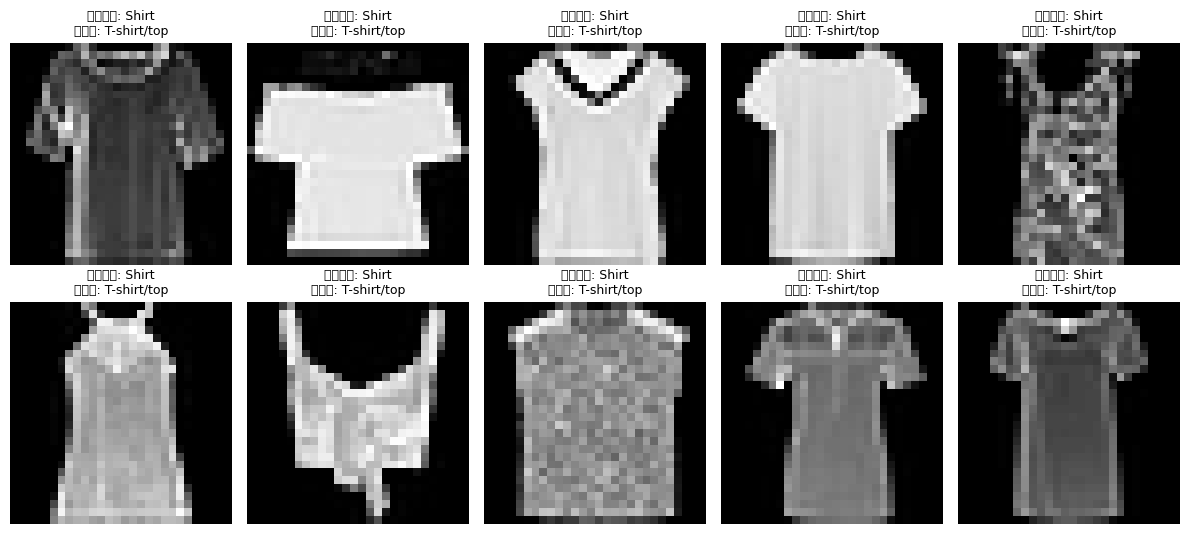

In [26]:
# หา index ของรูปที่ทายผิด
wrong_idx = np.where(all_preds != all_labels)[0]
print("จำนวนรูปที่ทายผิด:", len(wrong_idx))

# ดูเฉพาะกรณี Shirt ที่ถูกทายเป็น T-shirt/top (สับสนมากที่สุด)
shirt = class_names.index("Shirt")
tshirt = class_names.index("T-shirt/top")
target = [i for i in wrong_idx
          if all_labels[i] == shirt and all_preds[i] == tshirt][:10]

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for ax, i in zip(axes.flat, target):
    image, _ = test_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"จริง: {class_names[all_labels[i]]}\nทาย: {class_names[all_preds[i]]}",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [27]:
from torch.utils.data import Subset, DataLoader
from torchvision import datasets, transforms

mean, std = (0.2860,), (0.3530,)   # ค่าเฉลี่ย/ส่วนเบี่ยงเบนของ Fashion-MNIST

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),            # พลิกซ้าย-ขวา
    transforms.RandomCrop(28, padding=2),         # เลื่อนภาพเล็กน้อย
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25),             # ลบบางส่วนของภาพ
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_aug   = datasets.FashionMNIST("/content/data", train=True,  download=True, transform=train_tf)
train_plain = datasets.FashionMNIST("/content/data", train=True,  download=True, transform=eval_tf)
test_plain  = datasets.FashionMNIST("/content/data", train=False, download=True, transform=eval_tf)

# แบ่ง train/val ด้วย index ชุดเดียวกัน (seed เดิมเพื่อให้ซ้ำได้)
g = torch.Generator().manual_seed(42)
idx = torch.randperm(60000, generator=g).tolist()

train_loader2 = DataLoader(Subset(train_aug,   idx[:54000]), batch_size=128, shuffle=True)
val_loader2   = DataLoader(Subset(train_plain, idx[54000:]), batch_size=128, shuffle=False)
test_loader2  = DataLoader(test_plain, batch_size=128, shuffle=False)

print(len(train_loader2.dataset), len(val_loader2.dataset), len(test_loader2.dataset))

54000 6000 10000


In [28]:
import torch.nn as nn

class FashionCNNv2(nn.Module):
    def __init__(self):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2),
                nn.Dropout(0.25),
            )

        # [1,28,28] -> [32,14,14] -> [64,7,7] -> [128,3,3]
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 256), nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model2 = FashionCNNv2().to(device)
print("Parameters:", sum(p.numel() for p in model2.parameters()))

Parameters: 585066


In [29]:
import copy
import torch.optim as optim

epochs = 25
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model2.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = 0.0, None

for epoch in range(epochs):
    # --- train ---
    model2.train()
    loss_sum = correct = total = 0
    for x, y in train_loader2:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model2(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)
    tr_loss, tr_acc = loss_sum / total, correct / total

    # --- validate ---
    model2.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in val_loader2:
            x, y = x.to(device), y.to(device)
            out = model2(x)
            loss_sum += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    va_loss, va_acc = loss_sum / total, correct / total

    scheduler.step()   # ลด learning rate ตามรอบ

    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)

    if va_acc > best_val_acc:
        best_val_acc, best_state = va_acc, copy.deepcopy(model2.state_dict())

    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.2%} "
          f"| Val Loss: {va_loss:.4f} | Val Acc: {va_acc:.2%}")

model2.load_state_dict(best_state)
torch.save(best_state, "/content/best_fashion_cnn_v2.pth")
print(f"\nBest Val Acc: {best_val_acc:.2%}")

Epoch [1/25] | Train Loss: 0.6881 | Train Acc: 74.19% | Val Loss: 0.4090 | Val Acc: 85.12%
Epoch [2/25] | Train Loss: 0.4533 | Train Acc: 83.09% | Val Loss: 0.3347 | Val Acc: 87.50%
Epoch [3/25] | Train Loss: 0.3890 | Train Acc: 85.53% | Val Loss: 0.3100 | Val Acc: 88.73%
Epoch [4/25] | Train Loss: 0.3571 | Train Acc: 86.96% | Val Loss: 0.2735 | Val Acc: 89.62%
Epoch [5/25] | Train Loss: 0.3382 | Train Acc: 87.65% | Val Loss: 0.2531 | Val Acc: 90.70%
Epoch [6/25] | Train Loss: 0.3171 | Train Acc: 88.24% | Val Loss: 0.2535 | Val Acc: 90.22%
Epoch [7/25] | Train Loss: 0.3040 | Train Acc: 88.92% | Val Loss: 0.2363 | Val Acc: 91.08%
Epoch [8/25] | Train Loss: 0.2899 | Train Acc: 89.25% | Val Loss: 0.2308 | Val Acc: 90.92%
Epoch [9/25] | Train Loss: 0.2817 | Train Acc: 89.73% | Val Loss: 0.2103 | Val Acc: 91.77%
Epoch [10/25] | Train Loss: 0.2685 | Train Acc: 90.15% | Val Loss: 0.2223 | Val Acc: 91.85%
Epoch [11/25] | Train Loss: 0.2575 | Train Acc: 90.66% | Val Loss: 0.2042 | Val Acc: 92.8

In [30]:
model2.eval()
preds_v2, labels_v2 = [], []

with torch.no_grad():
    for x, y in test_loader2:            # ใช้ test_loader2 (ผ่าน Normalize)
        out = model2(x.to(device))
        preds_v2.extend(out.argmax(1).cpu().tolist())
        labels_v2.extend(y.tolist())

preds_v2 = np.array(preds_v2)
labels_v2 = np.array(labels_v2)
print(f"Test Accuracy v2: {(preds_v2 == labels_v2).mean():.2%}\n")

# เทียบ recall รายคลาส: v1 (all_preds จากขั้นที่ 2) กับ v2
print(f"{'Class':<14}{'v1':>8}{'v2':>8}{'diff':>8}")
for c, name in enumerate(class_names):
    mask = labels_v2 == c
    r1 = (all_preds[mask] == c).mean()
    r2 = (preds_v2[mask] == c).mean()
    print(f"{name:<14}{r1:>8.1%}{r2:>8.1%}{r2 - r1:>+8.1%}")

print()
print(classification_report(labels_v2, preds_v2, target_names=class_names, digits=3))

Test Accuracy v2: 93.57%

Class               v1      v2    diff
T-shirt/top      81.2%   88.7%   +7.5%
Trouser          97.8%   99.1%   +1.3%
Pullover         80.4%   90.3%   +9.9%
Dress            90.9%   93.9%   +3.0%
Coat             87.4%   91.7%   +4.3%
Sandal           98.7%   98.7%   +0.0%
Shirt            77.9%   79.9%   +2.0%
Sneaker          96.5%   98.1%   +1.6%
Bag              97.9%   99.1%   +1.2%
Ankle boot       94.1%   96.2%   +2.1%

              precision    recall  f1-score   support

 T-shirt/top      0.891     0.887     0.889      1000
     Trouser      0.995     0.991     0.993      1000
    Pullover      0.925     0.903     0.914      1000
       Dress      0.939     0.939     0.939      1000
        Coat      0.889     0.917     0.903      1000
      Sandal      0.986     0.987     0.987      1000
       Shirt      0.802     0.799     0.801      1000
     Sneaker      0.958     0.981     0.969      1000
         Bag      0.989     0.991     0.990      1000
  A

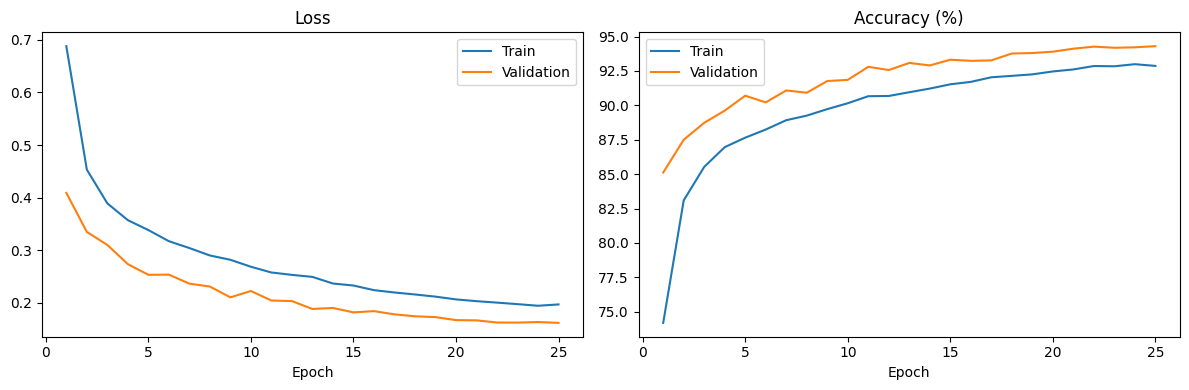

In [31]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], label="Train")
axes[0].plot(epochs_range, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, [a * 100 for a in history["train_acc"]], label="Train")
axes[1].plot(epochs_range, [a * 100 for a in history["val_acc"]], label="Validation")
axes[1].set_title("Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [32]:
from google.colab import files
files.download("/content/best_fashion_cnn_v2.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import os
print(os.path.exists("/content/best_fashion_cnn_v2.pth"))

True


In [35]:
model2 = FashionCNNv2().to(device)
model2.load_state_dict(torch.load("/content/best_fashion_cnn_v2.pth", map_location=device))
model2.eval()

FashionCNNv2(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.25, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, strid

In [38]:
from google.colab import files
from PIL import Image, ImageOps
import torch.nn.functional as F

def preprocess(path, invert=True, margin=0.05):
    img = Image.open(path).convert("L")
    img = ImageOps.autocontrast(img)
    if invert:
        img = ImageOps.invert(img)

    # หากรอบสี่เหลี่ยมของตัวเสื้อ (พิกเซลที่สว่างกว่าพื้นหลัง) แล้วครอป
    bbox = img.point(lambda p: 255 if p > 40 else 0).getbbox()
    if bbox:
        img = img.crop(bbox)

    w, h = img.size
    s = int(max(w, h) * (1 + 2 * margin))      # เผื่อขอบดำรอบๆ เล็กน้อย
    canvas = Image.new("L", (s, s), 0)
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas.resize((28, 28), Image.LANCZOS)

def predict(path, invert=True):
    img = preprocess(path, invert)
    x = eval_tf(img).unsqueeze(0).to(device)      # eval_tf = ToTensor + Normalize จากขั้นที่ 4
    model2.eval()
    with torch.no_grad():
        probs = F.softmax(model2(x), dim=1)[0].cpu()
    top = probs.topk(3)

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].imshow(Image.open(path).convert("RGB"))
    axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(img, cmap="gray")
    axes[1].set_title("What the model sees (28x28)"); axes[1].axis("off")
    plt.show()

    for p, i in zip(top.values, top.indices):
        print(f"{class_names[i]:<12} {p:.1%}")

Saving O1CN01V1AkDe1xc6R4ydCXO_2208843376463-0-cib-1.jpg to O1CN01V1AkDe1xc6R4ydCXO_2208843376463-0-cib-1 (7).jpg
==== O1CN01V1AkDe1xc6R4ydCXO_2208843376463-0-cib-1 (7).jpg


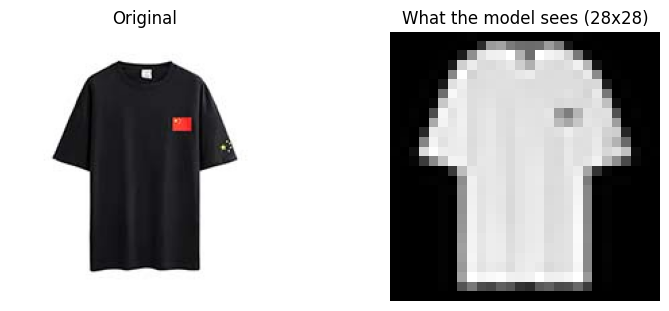

T-shirt/top  65.9%
Shirt        31.5%
Dress        2.1%


In [42]:
uploaded = files.upload()          # กดเลือกไฟล์รูปจากเครื่อง
for name in uploaded:
    print("====", name)
    predict(name, invert=True)     # ถ้าพื้นหลังรูปเป็นสีเข้มอยู่แล้ว ให้เปลี่ยนเป็น invert=False

Saving istockphoto-1278802435-612x612.jpg to istockphoto-1278802435-612x612 (2).jpg
==== istockphoto-1278802435-612x612 (2).jpg


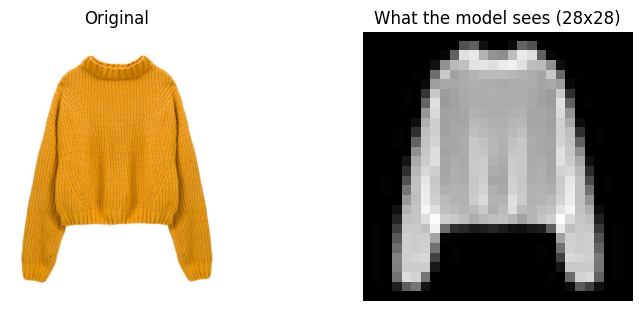

Pullover     89.2%
Shirt        8.4%
Coat         2.3%


In [44]:
uploaded = files.upload()          # กดเลือกไฟล์รูปจากเครื่อง
for name in uploaded:
    print("====", name)
    predict(name, invert=True)     # ถ้าพื้นหลังรูปเป็นสีเข้มอยู่แล้ว ให้เปลี่ยนเป็น invert=False